# 07 · External validation — real surveillance observations (ICMCIS)

BUBBLES and IDF-DS both observe aircraft through **cooperative telemetry**. If
the freshness effects reported so far were an artefact of that one mechanism,
this notebook would be where it shows: ICMCIS observes the same kind of target
with **radar**, an entirely independent sensing chain.

| Layer | Source |
|---|---|
| ground truth | onboard drone log (10 Hz), geodetic position + speed + yaw |
| observed | ALVIRA and ARCUS radar tracks, with the sensor's own timestamps |

> **Claim discipline.** ICMCIS is a counter-UAS detection and tracking research
> dataset, not an operational UTM. It validates the truth-versus-observation
> mechanism; it does not describe UTM performance.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

from telemetry_freshness.viz import style as S, figures as F
S.use_paper_style()
print("working dir:", ROOT)

working dir: /path/to/Field_Measurement_of_Age_of_Information


In [2]:
from telemetry_freshness.data.icmcis import IcmcisDataset
ds = IcmcisDataset()
SCENARIO = "train/Scenario_1_1"
gt = ds.load_scenario(SCENARIO)
dt = np.median(np.diff(gt[gt.uas_id == gt.uas_id.iloc[0]].t_s.to_numpy()))
print(f"scenarios available : {len(ds.scenarios())}")
print(f"ground truth        : {len(gt):,} rows, {gt.uas_id.nunique()} aircraft, "
      f"{gt.t_s.max():.0f} s, {1/dt:.1f} Hz")

scenarios available : 14
ground truth        : 7,979 rows, 1 aircraft, 798 s, 10.0 Hz


In [3]:
obs = {}
for sensor in ("ALVIRA", "ARCUS"):
    try:
        o = ds.load_observations(SCENARIO, sensor=sensor)
        obs[sensor] = o
        iv = o.track_interval_s.dropna(); iv = iv[(iv > 0) & (iv < 60)]
        print(f"{sensor:7s}: {len(o):6,} track rows | "
              f"update interval p50 {iv.median():.3f}s ({1/iv.median():.2f} Hz), p95 {iv.quantile(.95):.3f}s")
    except Exception as e:
        print(f"{sensor}: {type(e).__name__}: {e}")

ALVIRA :    162 track rows | update interval p50 1.309s (0.76 Hz), p95 1.320s
ARCUS  : 16,965 track rows | update interval p50 0.022s (45.45 Hz), p95 0.129s


### A caveat on the age measurement

The sensor track timestamp has millisecond resolution, but the row's record
clock is integer seconds. The observation age recoverable from ICMCIS is
therefore quantised to ~1 s and is a coarse figure. The **track update
interval** keeps full resolution and is the more trustworthy measure of how
often this surveillance chain refreshed a track.

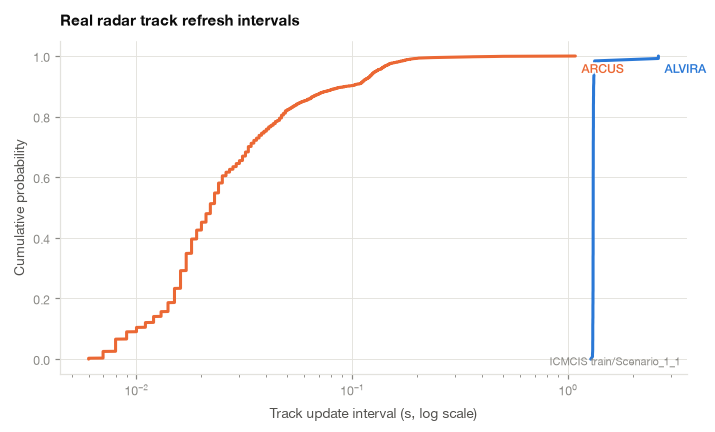

In [4]:
fig, ax = S.plt.subplots(figsize=(6.6, 4.0))
for (sensor, o), c in zip(obs.items(), S.categorical_colors(max(len(obs), 2))):
    iv = o.track_interval_s.dropna(); iv = iv[(iv > 0) & (iv < 30)].sort_values()
    if iv.empty: continue
    ax.plot(iv.to_numpy(), np.linspace(0, 1, iv.size), color=c, lw=2)
    S.direct_label(ax, iv.iloc[-1], 1.0, sensor, c, dy=-8)
ax.set_xscale("log"); ax.set_xlabel("Track update interval (s, log scale)")
ax.set_ylabel("Cumulative probability")
ax.set_title("Real radar track refresh intervals")
S.annotate_note(ax, f"ICMCIS {SCENARIO}")
S.finish(fig, ax); S.save(fig, "S9_icmcis_track_intervals"); S.plt.show()

## Truth versus observation in the plan view

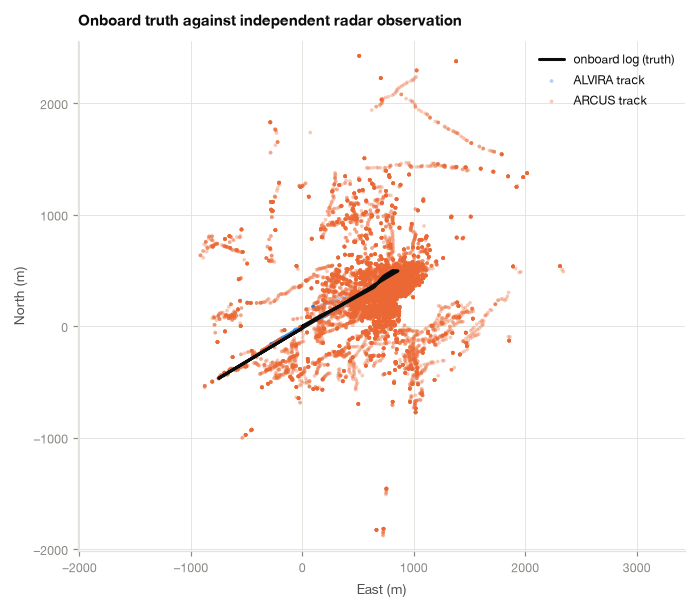

In [5]:
fig, ax = S.plt.subplots(figsize=(6.4, 5.6))
g = gt[gt.uas_id == gt.uas_id.iloc[0]]
ax.plot(g.x_m, g.y_m, color=S.INK["primary"], lw=2.0, label="onboard log (truth)", zorder=4)
for (sensor, o), c in zip(obs.items(), S.categorical_colors(max(len(obs), 2))):
    sub = o[(o.x_m.abs() < 3000) & (o.y_m.abs() < 3000)]
    ax.scatter(sub.x_m, sub.y_m, s=6, alpha=0.35, color=c, edgecolors="none", label=f"{sensor} track")
ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("East (m)"); ax.set_ylabel("North (m)")
ax.set_title("Onboard truth against independent radar observation")
ax.legend(loc="best")
S.finish(fig, ax); S.save(fig, "S10_icmcis_truth_vs_radar"); S.plt.show()

## Applying the same freshness machinery to a real sensor

The radar track stream is fed through the identical Age-of-Information
measurement used for the emulated links, so the numbers are directly
comparable with notebooks 02 and 04.

In [6]:
from telemetry_freshness.telemetry.message import TelemetryMessage
from telemetry_freshness.surveillance.state_store import SurveillanceStateStore
from telemetry_freshness.surveillance.age_of_information import freshness_errors
from telemetry_freshness.telemetry.generator import TrajectorySampler
from telemetry_freshness.core.schema import State

rows = []
sampler = TrajectorySampler(gt[gt.uas_id == gt.uas_id.iloc[0]])
for sensor, o in obs.items():
    sub = o.dropna(subset=["t_gen_s","x_m","y_m"]).sort_values("t_gen_s")
    sub = sub[sub.t_gen_s.between(sampler.t_start, sampler.t_end)]
    if len(sub) < 20:
        print(f"{sensor}: too few overlapping track rows"); continue
    store = SurveillanceStateStore()
    store.ingest([
        TelemetryMessage(
            uas_id=sampler.uas_id, t_gen_s=float(r.t_gen_s), t_arrive_s=float(r.t_gen_s),
            state=State(sampler.uas_id, float(r.t_gen_s), float(r.x_m), float(r.y_m),
                        float(r.z_m), float(r.vx_mps or 0), float(r.vy_mps or 0), 0.0))
        for r in sub.itertuples()
    ])
    t_eval = np.arange(sub.t_gen_s.min() + 2, sub.t_gen_s.max() - 2, 0.5)
    f = freshness_errors(store, sampler, t_eval)
    f = f[f.tracked].copy(); f["sensor"] = sensor
    rows.append(f)

if rows:
    E9 = pd.concat(rows, ignore_index=True)
    E9.to_parquet("results/raw/E9_icmcis_validation.parquet", index=False)
    display(E9.groupby("sensor").agg(
        n=("aoi_s","size"), aoi_p50=("aoi_s","median"), aoi_p95=("aoi_s", lambda s: s.quantile(.95)),
        err_p50=("horiz_error_m","median"), err_p95=("horiz_error_m", lambda s: s.quantile(.95))
    ).round(2))
else:
    print("No overlapping truth/track window in this scenario.")

,n,aoi_p50,aoi_p95,err_p50,err_p95
sensor,,,,,
ALVIRA,872,18.41,141.38,87.67,436.23
ARCUS,306,0.02,0.10,1337.52,1781.01


> The absolute error here mixes information age with the radar's own
> **measurement** error, which the cooperative-telemetry experiments do not
> have. The two cannot be separated from this data, so ICMCIS is used to
> confirm the *direction and mechanism* — observation age degrades the observed
> state — and not to produce a threshold.